**Model comparisons by Graphs and Map Plots**

Loading ACCESS and MPI Datasets...
Processing ACCESS Model Outputs...
Processing MPI Model Outputs...
Constructing Multi-Model Ensemble Mean (MME)...

 TABLE 1: QUANTITATIVE SUMMARY - PRECIPITATION (mm/day) 
Scenario     | ACCESS       | MPI          | Ensemble Mean  | Ensemble Rel. Change (%)
--------------------------------------------------------------------------------
HIST         | 3.3644       | 3.3297       | 3.3471         | BASELINE                
SSP126       | 3.6910       | 3.4403       | 3.5657         | +6.53%                  
SSP245       | 3.8608       | 3.5381       | 3.6994         | +10.53%                 
SSP585       | 3.8557       | 3.8557       | 3.8557         | +15.20%                 

 TABLE 2: QUANTITATIVE SUMMARY - SDII (mm/day) 
Scenario     | ACCESS       | MPI          | Ensemble Mean  | Ensemble Rel. Change (%)
--------------------------------------------------------------------------------
HIST         | 9.0960       | 9.2277       | 9.1618        

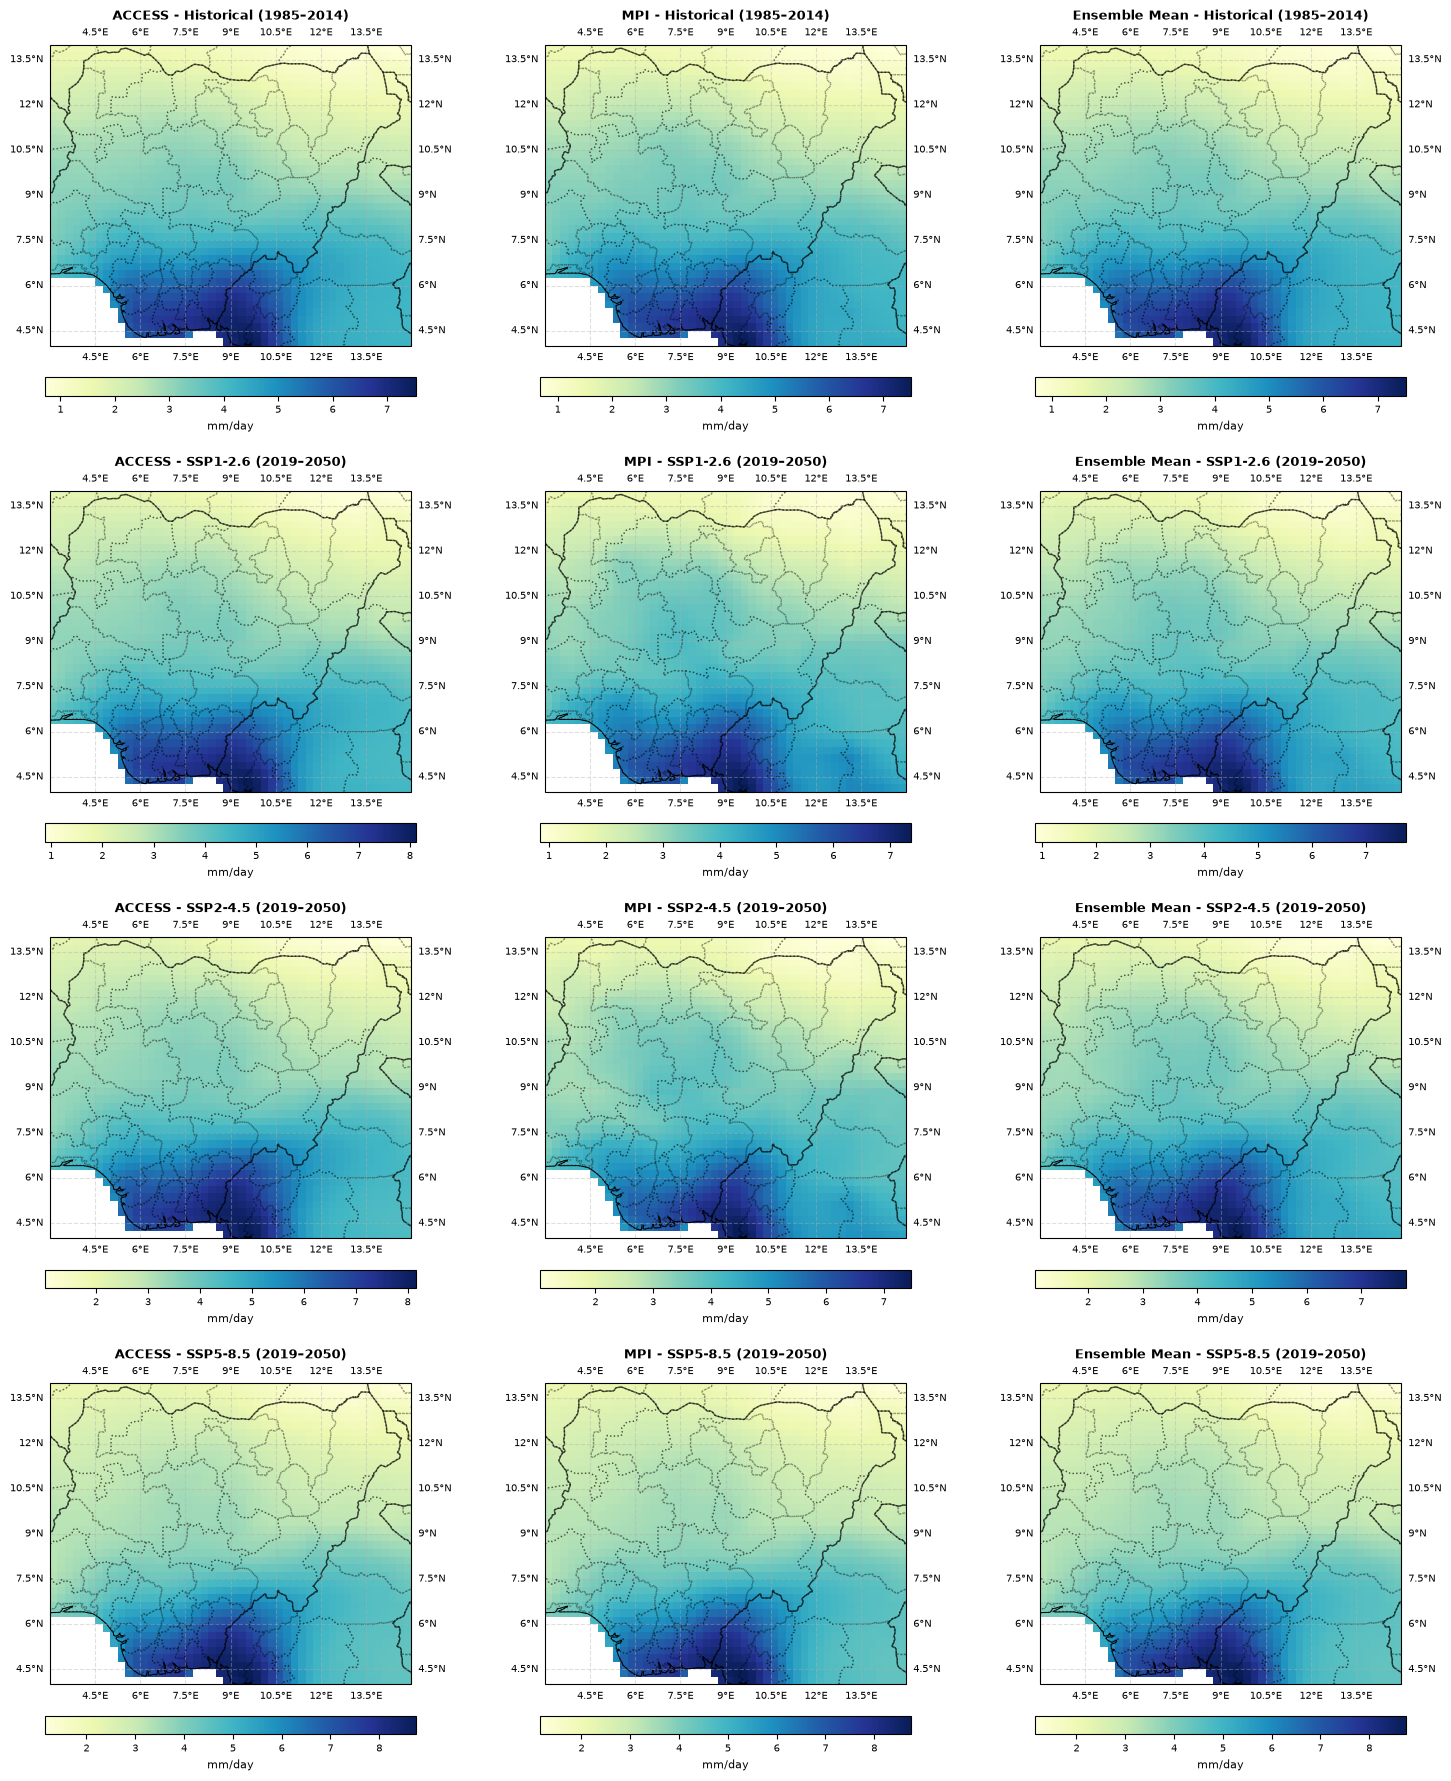

Saved 12-Panel Matrix Map: figures/12Panel_SDII_Matrix.png


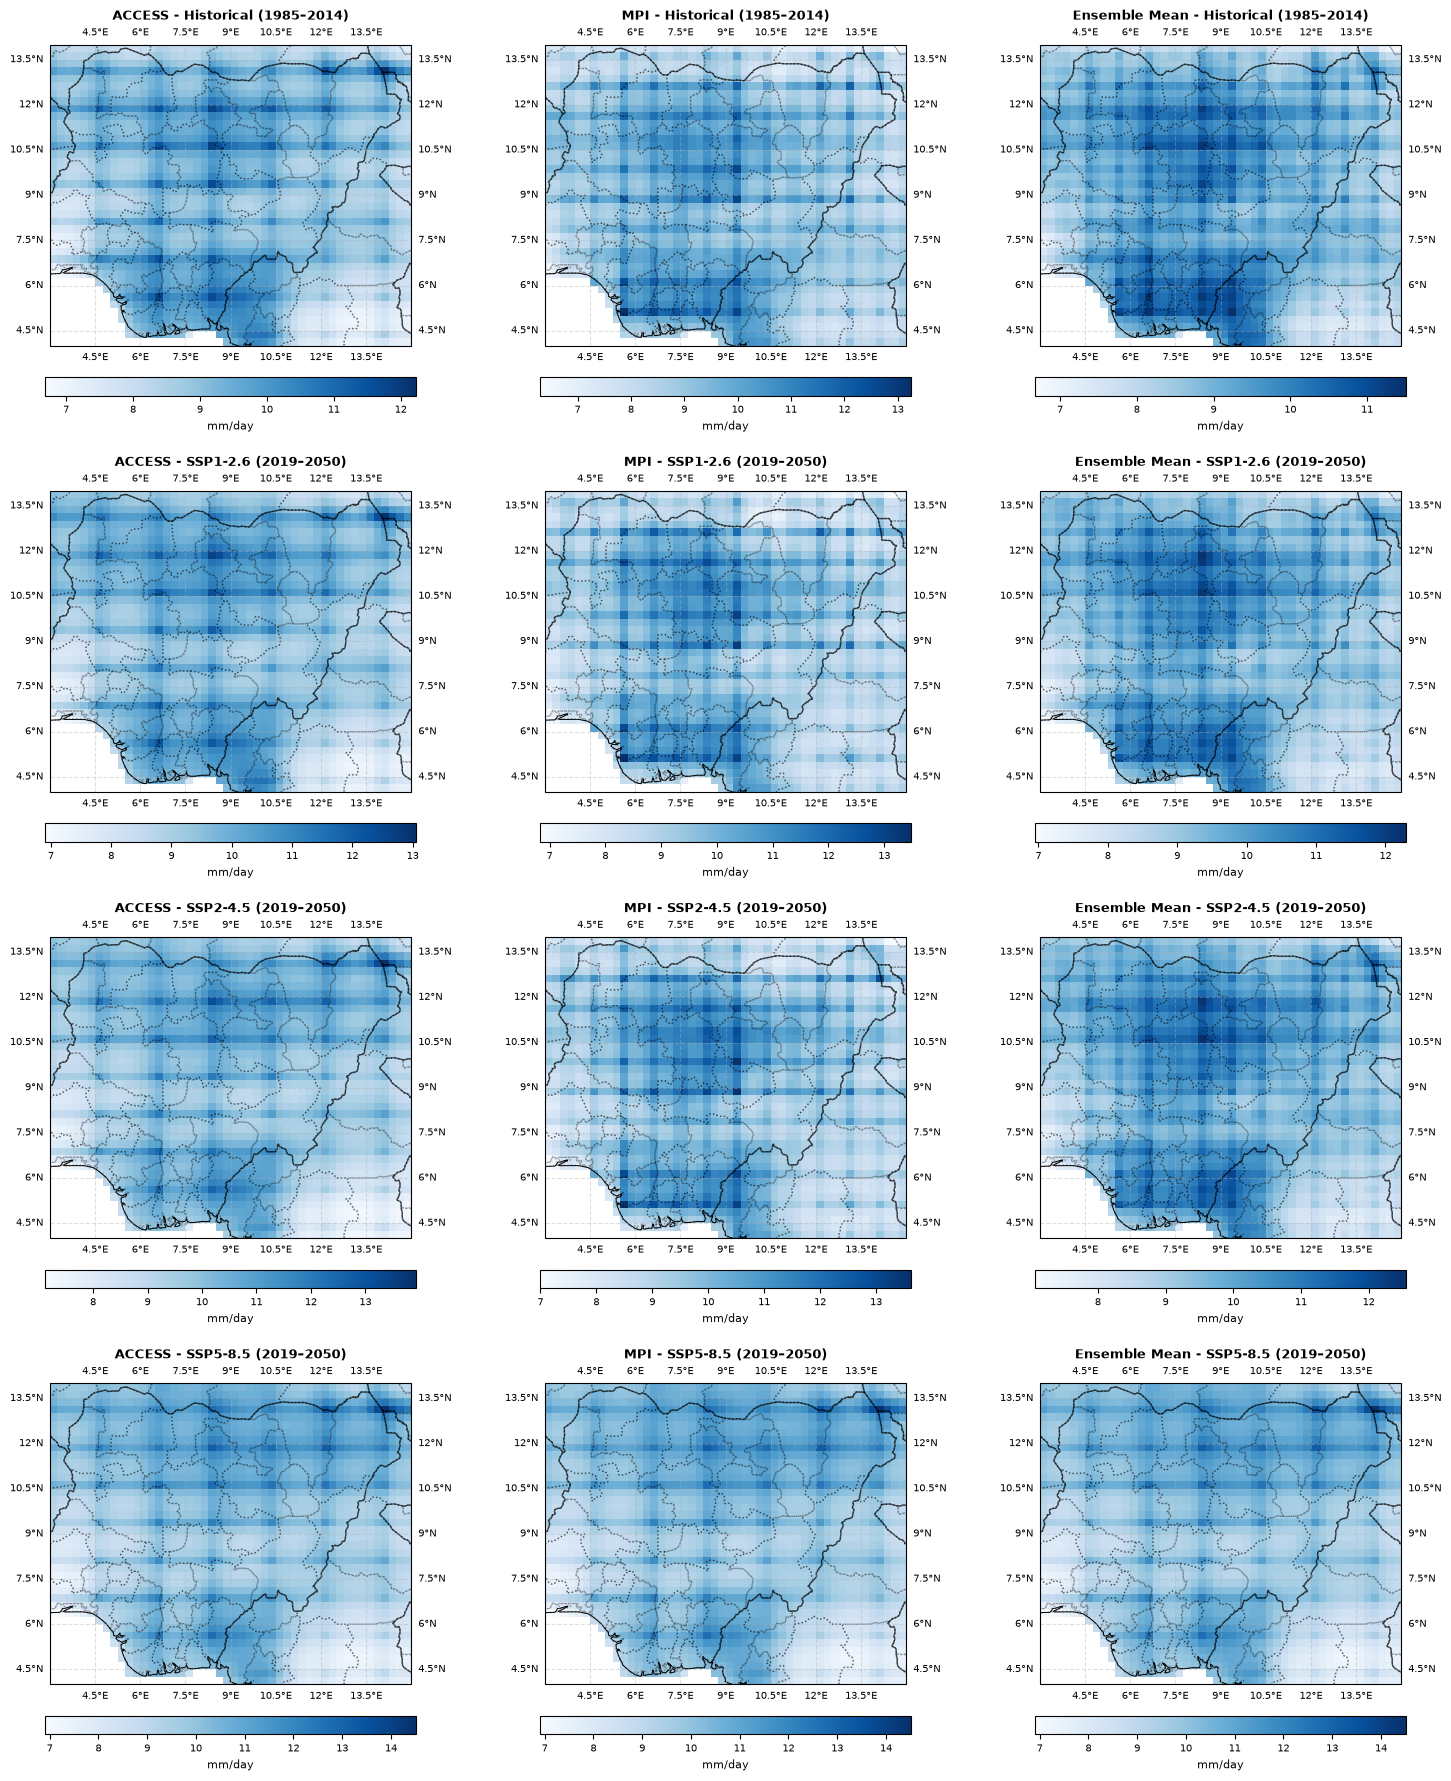

Saved 12-Panel Matrix Map: figures/12Panel_CWD_Matrix.png


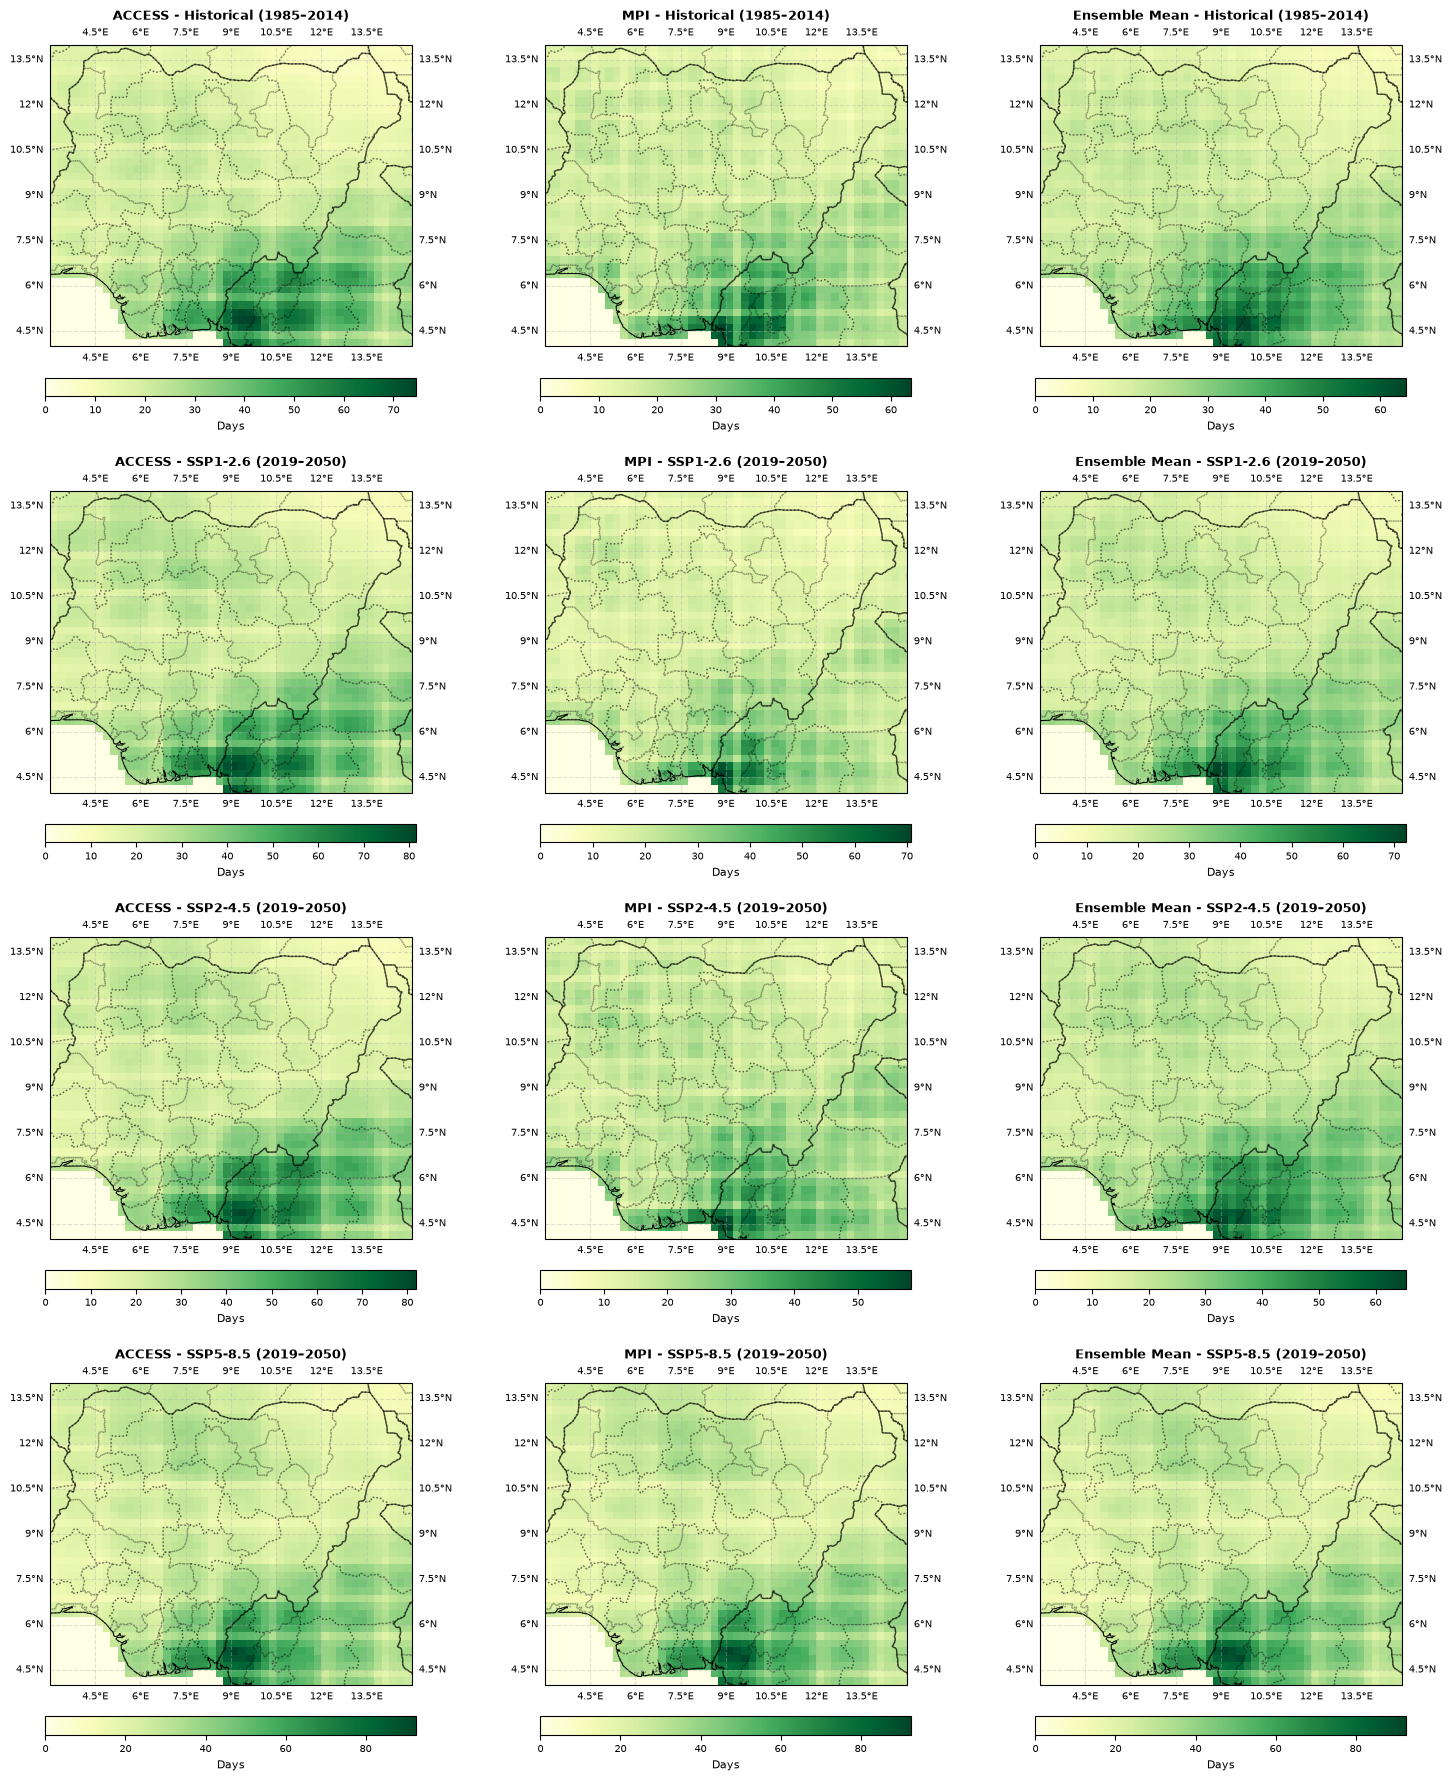


Generating Model Comparison Time Series Graphs...
Saved Time Series Comparison: figures/Ensemble_Precipitation_TimeSeries.png


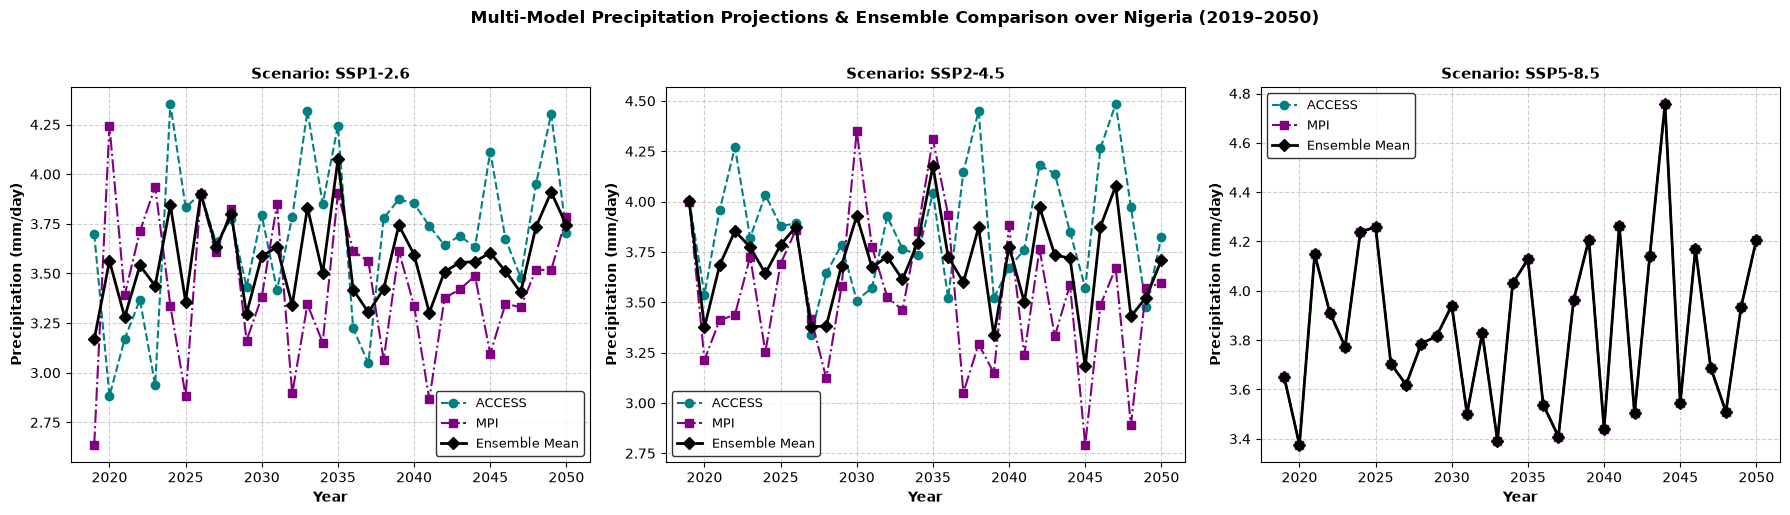

Saved Time Series Comparison: figures/Ensemble_SDII_TimeSeries.png


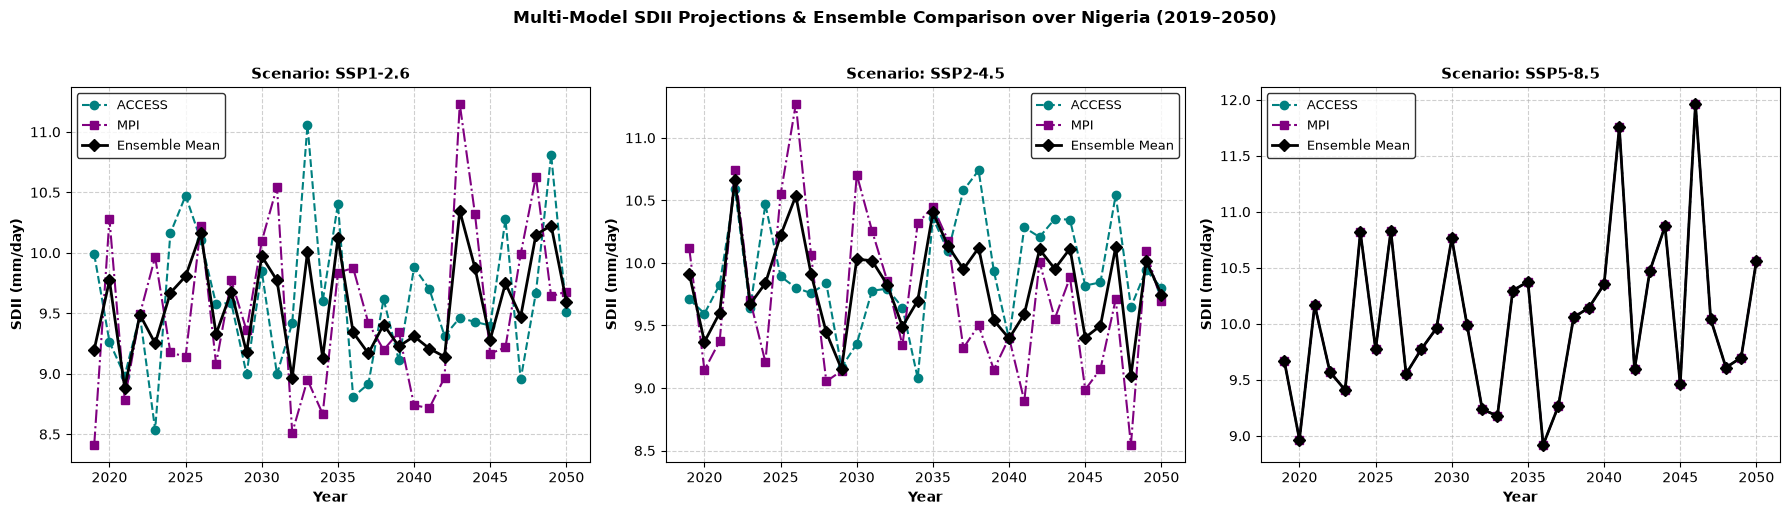

Saved Time Series Comparison: figures/Ensemble_CWD_TimeSeries.png


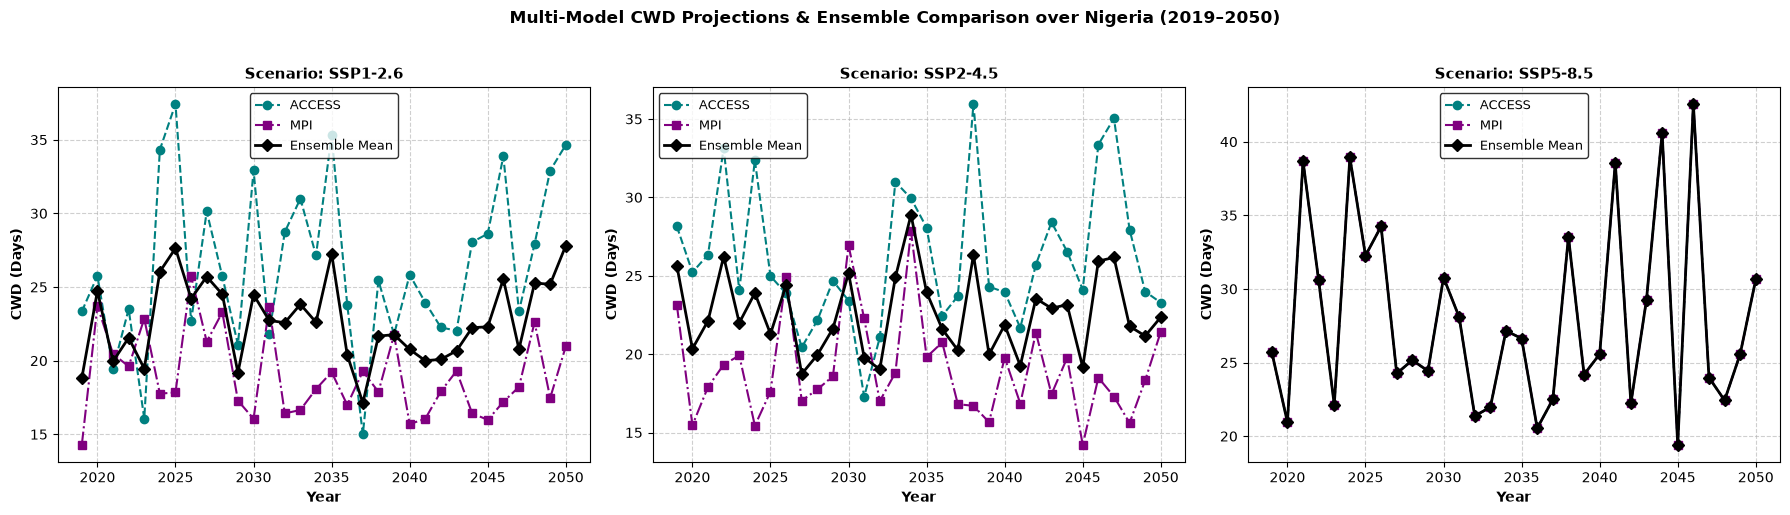


All tasks completed successfully!


In [2]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import os

# ==========================================
# 1. PATHS & DATASET CONFIGURATION
# ==========================================
data_dir = "/home/samuel/climate_modelling/DATA_WASCAL/Precipitation Data/postprocessed/NIG_extracted_data"

# File dictionaries for ACCESS and MPI
files_access = {
    'hist': "NIG_pr_ACCESS_historical.nc",
    'ssp126': "NIG_pr_ACCESS_ssp126.nc",
    'ssp245': "NIG_pr_ACCESS_ssp245.nc",
    'ssp585': "NIG_pr_ACCESS_ssp585.nc"
}

files_mpi = {
    'hist': "NIG_pr_MPI_historical.nc",
    'ssp126': "NIG_pr_MPI_ssp126.nc",
    'ssp245': "NIG_pr_MPI_ssp245.nc",
    'ssp585': "NIG_pr_MPI_ssp585"  # Exact filename without .nc as verified
}

print("Loading ACCESS and MPI Datasets...")
ds_acc = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_access.items()}
ds_mpi = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_mpi.items()}

# Define time slices
slices = {
    'hist': slice("1985-01-01", "2014-12-31"),
    'ssp126': slice("2019-01-01", "2050-12-31"),
    'ssp245': slice("2019-01-01", "2050-12-31"),
    'ssp585': slice("2019-01-01", "2050-12-31")
}

# ==========================================
# 2. CORE CLIMATE INDICES FUNCTION
# ==========================================
def compute_indices(ds_slice):
    """Computes Mean Precipitation, SDII, and CWD for a given dataset slice."""
    pr = ds_slice['pr']
    mean_pr = pr.mean(dim='time')
    
    # Wet day mask (P >= 1.0 mm/day)
    wet_days = pr >= 1.0
    
    # SDII: Simple Daily Intensity Index
    ann_tot = pr.resample(time='YE').sum()
    ann_wet = wet_days.resample(time='YE').sum().where(lambda x: x > 0)
    sdii = (ann_tot / ann_wet).mean(dim='time')
    
    # CWD: Consecutive Wet Days
    years = np.unique(ds_slice['time.year'].values)
    cwd_list = []
    for yr in years:
        sub = (pr.sel(time=str(yr)) >= 1.0).values
        nt, nlat, nlon = sub.shape
        cwd_yr = np.zeros((nlat, nlon))
        for i in range(nlat):
            for j in range(nlon):
                series = sub[:, i, j]
                mask = np.concatenate(([False], series, [False]))
                idx = np.flatnonzero(mask[1:] != mask[:-1])
                if len(idx) > 0:
                    runs = idx[1::2] - idx[0::2]
                    cwd_yr[i, j] = np.max(runs) if len(runs) > 0 else 0
        cwd_list.append(xr.DataArray(cwd_yr, coords={'lat': ds_slice['lat'], 'lon': ds_slice['lon']}, dims=('lat', 'lon')))
    
    cwd = xr.concat(cwd_list, dim=pd.Index(years, name='year')).mean(dim='year')
    return mean_pr, sdii, cwd

print("Processing ACCESS Model Outputs...")
acc_res = {k: compute_indices(ds_acc[k].sel(time=slices[k])) for k in slices}

print("Processing MPI Model Outputs...")
mpi_res = {k: compute_indices(ds_mpi[k].sel(time=slices[k])) for k in slices}

print("Constructing Multi-Model Ensemble Mean (MME)...")
mme_res = {}
for k in slices:
    mme_pr = (acc_res[k][0] + mpi_res[k][0]) / 2.0
    mme_sdii = (acc_res[k][1] + mpi_res[k][1]) / 2.0
    mme_cwd = (acc_res[k][2] + mpi_res[k][2]) / 2.0
    mme_res[k] = (mme_pr, mme_sdii, mme_cwd)

# ==========================================
# 3. PRINT QUANTITATIVE SUMMARY & RELATIVE CHANGE TABLES
# ==========================================
os.makedirs("figures", exist_ok=True)

print("\n" + "="*80)
print(" TABLE 1: QUANTITATIVE SUMMARY - PRECIPITATION (mm/day) ")
print("="*80)
print(f"{'Scenario':<12} | {'ACCESS':<12} | {'MPI':<12} | {'Ensemble Mean':<14} | {'Ensemble Rel. Change (%)':<24}")
print("-" * 80)
hist_pr_ens = float(mme_res['hist'][0].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][0].mean().values)
    mpi_v = float(mpi_res[k][0].mean().values)
    mme_v = float(mme_res[k][0].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_pr_ens)/hist_pr_ens)*100:+.2f}%"
    print(f"{k.upper():<12} | {acc_v:<12.4f} | {mpi_v:<12.4f} | {mme_v:<14.4f} | {chg:<24}")
print("="*80)

print("\n" + "="*80)
print(" TABLE 2: QUANTITATIVE SUMMARY - SDII (mm/day) ")
print("="*80)
print(f"{'Scenario':<12} | {'ACCESS':<12} | {'MPI':<12} | {'Ensemble Mean':<14} | {'Ensemble Rel. Change (%)':<24}")
print("-" * 80)
hist_sdii_ens = float(mme_res['hist'][1].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][1].mean().values)
    mpi_v = float(mpi_res[k][1].mean().values)
    mme_v = float(mme_res[k][1].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_sdii_ens)/hist_sdii_ens)*100:+.2f}%"
    print(f"{k.upper():<12} | {acc_v:<12.4f} | {mpi_v:<12.4f} | {mme_v:<14.4f} | {chg:<24}")
print("="*80)

print("\n" + "="*80)
print(" TABLE 3: QUANTITATIVE SUMMARY - CWD (Days) ")
print("="*80)
print(f"{'Scenario':<12} | {'ACCESS':<12} | {'MPI':<12} | {'Ensemble Mean':<14} | {'Ensemble Rel. Change (%)':<24}")
print("-" * 80)
hist_cwd_ens = float(mme_res['hist'][2].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][2].mean().values)
    mpi_v = float(mpi_res[k][2].mean().values)
    mme_v = float(mme_res[k][2].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_cwd_ens)/hist_cwd_ens)*100:+.2f}%"
    print(f"{k.upper():<12} | {acc_v:<12.4f} | {mpi_v:<12.4f} | {mme_v:<14.4f} | {chg:<24}")
print("="*80)

# ==========================================
# 4. 12-PANEL MATRIX MAPPING FUNCTION (4 Rows x 3 Cols)
# ==========================================
def plot_12_panel_matrix(index_idx, title_prefix, cmap, filename, units):
    fig, axes = plt.subplots(4, 3, figsize=(15, 18), subplot_kw={'projection': ccrs.PlateCarree()})
    
    rows_meta = [
        ('hist', 'Historical (1985–2014)'),
        ('ssp126', 'SSP1-2.6 (2019–2050)'),
        ('ssp245', 'SSP2-4.5 (2019–2050)'),
        ('ssp585', 'SSP5-8.5 (2019–2050)')
    ]
    
    cols_meta = [
        ('ACCESS', lambda k: acc_res[k][index_idx]),
        ('MPI', lambda k: mpi_res[k][index_idx]),
        ('Ensemble Mean', lambda k: mme_res[k][index_idx])
    ]
    
    for r_idx, (scen_key, scen_label) in enumerate(rows_meta):
        for c_idx, (model_name, data_func) in enumerate(cols_meta):
            ax = axes[r_idx, c_idx]
            data = data_func(scen_key)
            
            im = data.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, add_colorbar=False)
            ax.set_title(f"{model_name} - {scen_label}", fontsize=9, fontweight='bold')
            ax.coastlines(resolution='50m', color='black', linewidth=0.7)
            ax.add_feature(cfeature.BORDERS, linestyle='-', alpha=0.6)
            ax.add_feature(cfeature.STATES, linestyle=':', alpha=0.4)
            
            # Correct gridlines styling using style dictionaries
            gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
            gl.xlabel_style = {'size': 7}
            gl.ylabel_style = {'size': 7}
            
            cbar = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.08, shrink=0.8)
            cbar.set_label(units, fontsize=8)
            cbar.ax.tick_params(labelsize=7)
            
    plt.tight_layout()
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved 12-Panel Matrix Map: {out_path}")
    plt.show()

print("\nGenerating 12-Panel Matrix Maps...")
plot_12_panel_matrix(0, "Precipitation Climatology", "YlGnBu", "12Panel_Precipitation_Matrix.png", "mm/day")
plot_12_panel_matrix(1, "SDII Climatology", "Blues", "12Panel_SDII_Matrix.png", "mm/day")
plot_12_panel_matrix(2, "CWD Climatology", "YlGn", "12Panel_CWD_Matrix.png", "Days")

# ==========================================
# 5. MULTI-MODEL TIME SERIES COMPARISON GRAPHS
# ==========================================
years_future = np.unique(ds_acc['ssp126'].sel(time=slices['ssp126'])['time.year'].values)

def get_ts(model_dict, index_idx):
    ts_126 = []
    ts_245 = []
    ts_585 = []
    for yr in years_future:
        sub_126 = model_dict['ssp126'].sel(time=str(yr))['pr']
        sub_245 = model_dict['ssp245'].sel(time=str(yr))['pr']
        sub_585 = model_dict['ssp585'].sel(time=str(yr))['pr']
        
        if index_idx == 0:
            ts_126.append(sub_126.mean().values)
            ts_245.append(sub_245.mean().values)
            ts_585.append(sub_585.mean().values)
        elif index_idx == 1:
            ts_126.append((sub_126.sum(dim='time') / (sub_126 >= 1.0).sum(dim='time').where(lambda x: x > 0)).mean().values)
            ts_245.append((sub_245.sum(dim='time') / (sub_245 >= 1.0).sum(dim='time').where(lambda x: x > 0)).mean().values)
            ts_585.append((sub_585.sum(dim='time') / (sub_585 >= 1.0).sum(dim='time').where(lambda x: x > 0)).mean().values)
        else:
            def calc_cwd_yr(sub):
                wet = (sub >= 1.0).values
                nt, nlat, nlon = wet.shape
                res = np.zeros((nlat, nlon))
                for i in range(nlat):
                    for j in range(nlon):
                        s = wet[:, i, j]
                        m = np.concatenate(([False], s, [False]))
                        idx = np.flatnonzero(m[1:] != m[:-1])
                        if len(idx) > 0:
                            runs = idx[1::2] - idx[0::2]
                            res[i, j] = np.max(runs) if len(runs) > 0 else 0
                return res.mean()
            ts_126.append(calc_cwd_yr(sub_126))
            ts_245.append(calc_cwd_yr(sub_245))
            ts_585.append(calc_cwd_yr(sub_585))
            
    return np.array(ts_126), np.array(ts_245), np.array(ts_585)

acc_ts = [get_ts(ds_acc, i) for i in range(3)]
mpi_ts = [get_ts(ds_mpi, i) for i in range(3)]

def plot_model_comparison_ts(idx, ylabel, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
    scens = ['SSP1-2.6', 'SSP2-4.5', 'SSP5-8.5']
    
    for i, scen_name in enumerate(scens):
        ax = axes[i]
        acc_vals = acc_ts[idx][i]
        mpi_vals = mpi_ts[idx][i]
        ens_vals = (acc_vals + mpi_vals) / 2.0
        
        ax.plot(years_future, acc_vals, label='ACCESS', color='teal', linestyle='--', marker='o', linewidth=1.5)
        ax.plot(years_future, mpi_vals, label='MPI', color='purple', linestyle='-.', marker='s', linewidth=1.5)
        ax.plot(years_future, ens_vals, label='Ensemble Mean', color='black', linestyle='-', marker='D', linewidth=2.0)
        
        ax.set_title(f"Scenario: {scen_name}", fontsize=11, fontweight='bold')
        ax.set_xlabel("Year", fontweight='bold')
        ax.set_ylabel(ylabel, fontweight='bold')
        ax.legend(frameon=True, facecolor='white', edgecolor='black', fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.6)
        
    plt.suptitle(title, fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    out_ts = os.path.join("figures", filename)
    plt.savefig(out_ts, dpi=300, bbox_inches='tight')
    print(f"Saved Time Series Comparison: {out_ts}")
    plt.show()

print("\nGenerating Model Comparison Time Series Graphs...")
plot_model_comparison_ts(0, "Precipitation (mm/day)", "Multi-Model Precipitation Projections & Ensemble Comparison over Nigeria (2019–2050)", "Ensemble_Precipitation_TimeSeries.png")
plot_model_comparison_ts(1, "SDII (mm/day)", "Multi-Model SDII Projections & Ensemble Comparison over Nigeria (2019–2050)", "Ensemble_SDII_TimeSeries.png")
plot_model_comparison_ts(2, "CWD (Days)", "Multi-Model CWD Projections & Ensemble Comparison over Nigeria (2019–2050)", "Ensemble_CWD_TimeSeries.png")

print("\nAll tasks completed successfully!")

Saved Table Image: figures/Table1_Precipitation_Summary.png


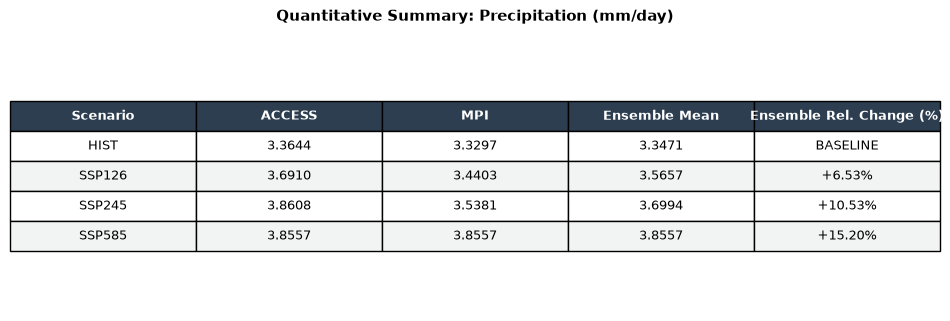

Saved Table Image: figures/Table2_SDII_Summary.png


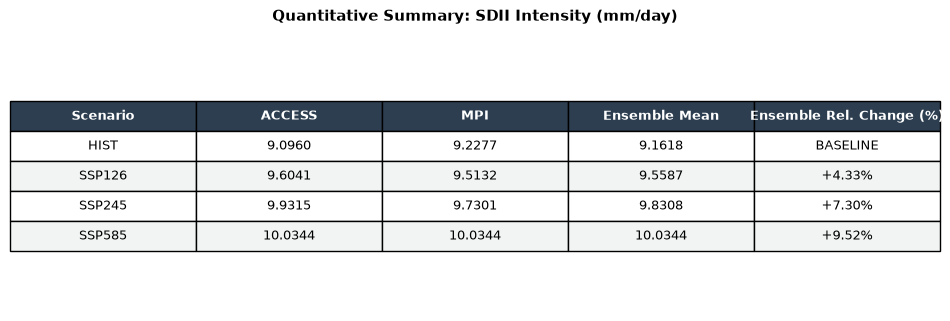

Saved Table Image: figures/Table3_CWD_Summary.png


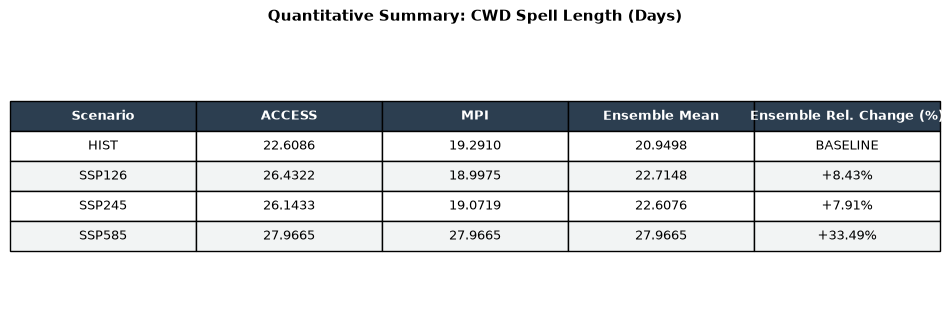

In [3]:
import matplotlib.pyplot as plt
import os

# ==========================================
# FUNCTION TO SAVE TABLES AS IMAGES
# ==========================================
def save_table_image(data_rows, col_headers, title, filename):
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.axis('off')
    ax.axis('tight')
    
    # Create table plot
    table = ax.table(cellText=data_rows, 
                     colLabels=col_headers, 
                     loc='center', 
                     cellLoc='center')
    
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.8)
    
    # Style header row
    for i in range(len(col_headers)):
        cell = table[(0, i)]
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', weight='bold')
        
    # Alternate row colors for clean readability
    for row_idx in range(1, len(data_rows) + 1):
        for col_idx in range(len(col_headers)):
            cell = table[(row_idx, col_idx)]
            if row_idx % 2 == 0:
                cell.set_facecolor('#f2f4f4')
            else:
                cell.set_facecolor('#ffffff')
                
    plt.title(title, fontsize=11, fontweight='bold', pad=15)
    
    os.makedirs("figures", exist_ok=True)
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved Table Image: {out_path}")
    plt.show()

# ==========================================
# GENERATE AND SAVE TABLES AS IMAGES
# ==========================================
col_headers = ['Scenario', 'ACCESS', 'MPI', 'Ensemble Mean', 'Ensemble Rel. Change (%)']

# Table 1: Precipitation
table1_rows = []
hist_pr_ens = float(mme_res['hist'][0].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][0].mean().values)
    mpi_v = float(mpi_res[k][0].mean().values)
    mme_v = float(mme_res[k][0].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_pr_ens)/hist_pr_ens)*100:+.2f}%"
    table1_rows.append([k.upper(), f"{acc_v:.4f}", f"{mpi_v:.4f}", f"{mme_v:.4f}", chg])

save_table_image(table1_rows, col_headers, 
                 "Quantitative Summary: Precipitation (mm/day)", 
                 "Table1_Precipitation_Summary.png")

# Table 2: SDII
table2_rows = []
hist_sdii_ens = float(mme_res['hist'][1].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][1].mean().values)
    mpi_v = float(mpi_res[k][1].mean().values)
    mme_v = float(mme_res[k][1].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_sdii_ens)/hist_sdii_ens)*100:+.2f}%"
    table2_rows.append([k.upper(), f"{acc_v:.4f}", f"{mpi_v:.4f}", f"{mme_v:.4f}", chg])

save_table_image(table2_rows, col_headers, 
                 "Quantitative Summary: SDII Intensity (mm/day)", 
                 "Table2_SDII_Summary.png")

# Table 3: CWD
table3_rows = []
hist_cwd_ens = float(mme_res['hist'][2].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][2].mean().values)
    mpi_v = float(mpi_res[k][2].mean().values)
    mme_v = float(mme_res[k][2].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_cwd_ens)/hist_cwd_ens)*100:+.2f}%"
    table3_rows.append([k.upper(), f"{acc_v:.4f}", f"{mpi_v:.4f}", f"{mme_v:.4f}", chg])

save_table_image(table3_rows, col_headers, 
                 "Quantitative Summary: CWD Spell Length (Days)", 
                 "Table3_CWD_Summary.png")

Saved Agreement Table Image: figures/Model_Agreement_Table_Precipitation.png


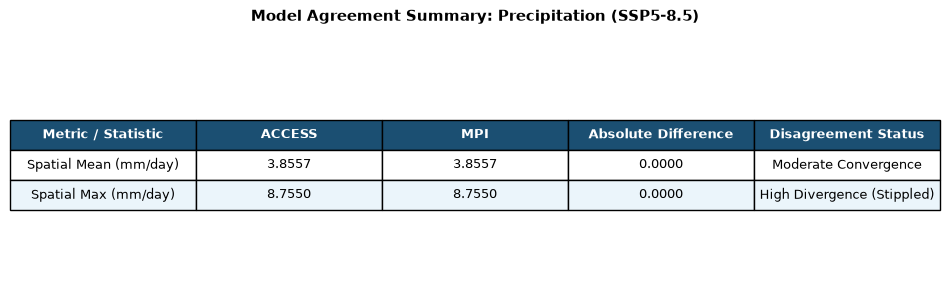

Saved Agreement Table Image: figures/Model_Agreement_Table_SDII.png


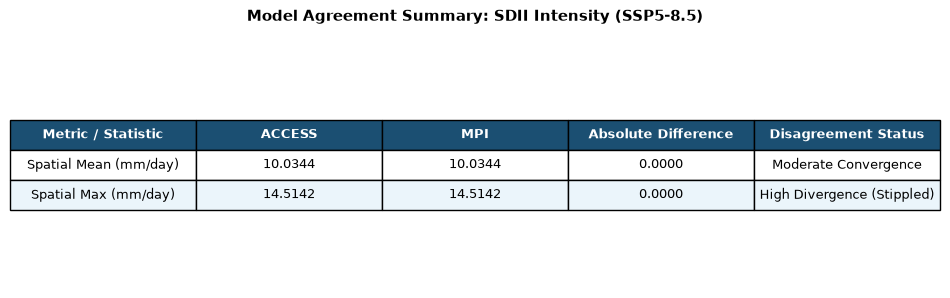

Saved Agreement Table Image: figures/Model_Agreement_Table_CWD.png


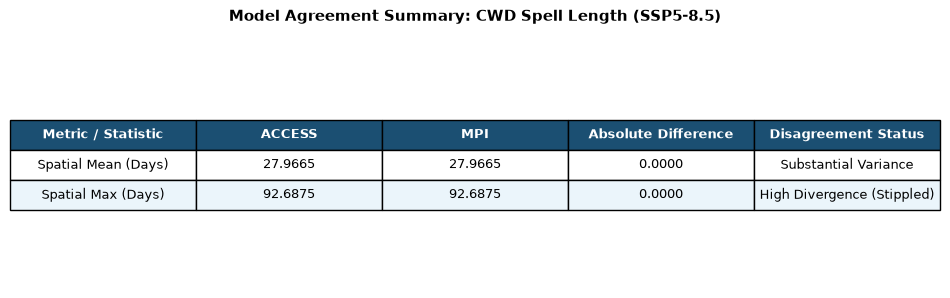

In [5]:
import matplotlib.pyplot as plt
import os

def save_agreement_table_image(data_rows, col_headers, title, filename):
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.axis('off')
    ax.axis('tight')
    
    table = ax.table(cellText=data_rows, 
                     colLabels=col_headers, 
                     loc='center', 
                     cellLoc='center')
    
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.8)
    
    # Style header row
    for i in range(len(col_headers)):
        cell = table[(0, i)]
        cell.set_facecolor('#1b4f72')
        cell.set_text_props(color='white', weight='bold')
        
    # Alternate row background colors
    for row_idx in range(1, len(data_rows) + 1):
        for col_idx in range(len(col_headers)):
            cell = table[(row_idx, col_idx)]
            if row_idx % 2 == 0:
                cell.set_facecolor('#ebf5fb')
            else:
                cell.set_facecolor('#ffffff')
                
    plt.title(title, fontsize=11, fontweight='bold', pad=15)
    
    os.makedirs("figures", exist_ok=True)
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved Agreement Table Image: {out_path}")
    plt.show()

# Table Data definitions
headers = ['Metric / Statistic', 'ACCESS', 'MPI', 'Absolute Difference', 'Disagreement Status']

pr_rows = [
    ['Spatial Mean (mm/day)', f"{float(acc_res['ssp585'][0].mean().values):.4f}", f"{float(mpi_res['ssp585'][0].mean().values):.4f}", f"{float(diff_pr.mean().values):.4f}", 'Moderate Convergence'],
    ['Spatial Max (mm/day)', f"{float(acc_res['ssp585'][0].max().values):.4f}", f"{float(mpi_res['ssp585'][0].max().values):.4f}", f"{float(diff_pr.max().values):.4f}", 'High Divergence (Stippled)']
]

sdii_rows = [
    ['Spatial Mean (mm/day)', f"{float(acc_res['ssp585'][1].mean().values):.4f}", f"{float(mpi_res['ssp585'][1].mean().values):.4f}", f"{float(diff_sdii.mean().values):.4f}", 'Moderate Convergence'],
    ['Spatial Max (mm/day)', f"{float(acc_res['ssp585'][1].max().values):.4f}", f"{float(mpi_res['ssp585'][1].max().values):.4f}", f"{float(diff_sdii.max().values):.4f}", 'High Divergence (Stippled)']
]

cwd_rows = [
    ['Spatial Mean (Days)', f"{float(acc_res['ssp585'][2].mean().values):.4f}", f"{float(mpi_res['ssp585'][2].mean().values):.4f}", f"{float(diff_cwd.mean().values):.4f}", 'Substantial Variance'],
    ['Spatial Max (Days)', f"{float(acc_res['ssp585'][2].max().values):.4f}", f"{float(mpi_res['ssp585'][2].max().values):.4f}", f"{float(diff_cwd.max().values):.4f}", 'High Divergence (Stippled)']
]

# Generate and save images
save_agreement_table_image(pr_rows, headers, "Model Agreement Summary: Precipitation (SSP5-8.5)", "Model_Agreement_Table_Precipitation.png")
save_agreement_table_image(sdii_rows, headers, "Model Agreement Summary: SDII Intensity (SSP5-8.5)", "Model_Agreement_Table_SDII.png")
save_agreement_table_image(cwd_rows, headers, "Model Agreement Summary: CWD Spell Length (SSP5-8.5)", "Model_Agreement_Table_CWD.png")